In [1]:
#imports
import numpy as np
import pandas as pd
import io
import time
import heapq
import random
import matplotlib.pyplot as plt
from statistics import mean
from collections import deque

In [2]:
# Data source: DOT Consumer Airfare Report - Table 1a (All U.S. Airport Pair Markets).
# Download table1a.csv from https://datahub.transportation.gov/d/tfrh-tu9e
# and place it in the same folder as this notebook.

In [3]:
#load Table 1a (DOT Consumer Airfare Report) from a local file
flight_data = pd.read_csv('table1a.csv')

# Table 1a stores numbers as formatted strings (e.g. $132.68 or 1,138); convert to numeric
for c in ['fare', 'fare_lg', 'fare_low']:
    flight_data[c] = flight_data[c].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
for c in ['nsmiles', 'passengers']:
    flight_data[c] = flight_data[c].astype(str).str.replace(',', '', regex=False).astype(int)

C:\Users\shawn\AppData\Local\Temp\ipykernel_24916\1846857845.py:2: DtypeWarning: Columns (20: Geocoded_City1, 22: Geocoded_City1 (city), 25: Geocoded_City2, 27: Geocoded_City2 (city)) have mixed types. Specify dtype option on import or set low_memory=False.
  flight_data = pd.read_csv('table1a.csv')


In [4]:
flight_data

,tbl,Year,quarter,citymarketid_1,citymarketid_2,city1,city2,airportid_1,airportid_2,airport_1,...,Geocoded_City1 (address),Geocoded_City1 (city),Geocoded_City1 (state),Geocoded_City1 (zip),Geocoded_City2,Geocoded_City2 (address),Geocoded_City2 (city),Geocoded_City2 (state),Geocoded_City2 (zip),tbl1apk
0,Table1a,2026,1,30257,33195,"Albany, NY","Tampa, FL (Metropolitan Area)",10257,14112,ALB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202611025714112ALBPIE
1,Table1a,2026,1,30257,30852,"Albany, NY","Washington, DC (Metropolitan Area)",10257,10821,ALB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202611025710821ALBBWI
2,Table1a,2026,1,30257,30852,"Albany, NY","Washington, DC (Metropolitan Area)",10257,11278,ALB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202611025711278ALBDCA
3,Table1a,2026,1,30257,30852,"Albany, NY","Washington, DC (Metropolitan Area)",10257,12264,ALB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202611025712264ALBIAD
4,Table1a,2026,1,30257,32467,"Albany, NY","Miami, FL (Metropolitan Area)",10257,13303,ALB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202611025713303ALBMIA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
262082,Table 1a,1993,1,34653,30852,"Tulsa, OK","Washington, DC (Metropolitan Area)",15370,12264,TUL,...,NaN,"Tulsa, OK",NaN,NaN,POINT (-77.019912 38.892062),NaN,"Washington, DC (Metropolitan Area)",NaN,NaN,199311537012264TULIAD
262083,Table 1a,1993,1,30852,34027,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",12264,14027,IAD,...,NaN,"Washington, DC (Metropolitan Area)",NaN,NaN,POINT (-98.500854 33.90976),NaN,"West Palm Beach/Palm Beach, FL",NaN,NaN,199311226414027IADPBI
262084,Table 1a,1993,1,30852,34027,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",10821,14027,BWI,...,NaN,"Washington, DC (Metropolitan Area)",NaN,NaN,POINT (-98.500854 33.90976),NaN,"West Palm Beach/Palm Beach, FL",NaN,NaN,199311082114027BWIPBI
262085,Table 1a,1993,1,30852,34027,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",11278,14027,DCA,...,NaN,"Washington, DC (Metropolitan Area)",NaN,NaN,POINT (-98.500854 33.90976),NaN,"West Palm Beach/Palm Beach, FL",NaN,NaN,199311127814027DCAPBI


In [5]:
#keep only the columns needed for the graph (works for both the Kaggle and Table 1a exports)
keep = ['Year', 'quarter', 'city1', 'city2', 'airport_1', 'airport_2', 'nsmiles', 'passengers', 'fare', 'carrier_lg', 'fare_lg', 'carrier_low', 'fare_low']
flight_data = flight_data[keep]

In [6]:
flight_data

,Year,quarter,city1,city2,airport_1,airport_2,nsmiles,passengers,fare,carrier_lg,fare_lg,carrier_low,fare_low
0,2026,1,"Albany, NY","Tampa, FL (Metropolitan Area)",ALB,PIE,1138,92,132.68,G4,132.68,G4,132.68
1,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,BWI,324,85,258.94,WN,258.19,WN,258.19
2,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,DCA,324,125,253.46,AA,254.06,WN,198.72
3,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,IAD,324,64,251.98,UA,251.09,UA,251.09
4,2026,1,"Albany, NY","Miami, FL (Metropolitan Area)",ALB,MIA,1225,75,292.23,WN,245.43,WN,245.43
...,...,...,...,...,...,...,...,...,...,...,...,...,...
262082,1993,1,"Tulsa, OK","Washington, DC (Metropolitan Area)",TUL,IAD,1071,20,247.47,AA,268.40,TW,181.67
262083,1993,1,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",IAD,PBI,883,45,190.54,UA,190.82,DL,189.69
262084,1993,1,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",BWI,PBI,883,188,193.86,US,189.59,US,189.59
262085,1993,1,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",DCA,PBI,883,325,202.27,US,203.78,US,203.78


In [7]:
#removing years before 2018
flight_data = flight_data[flight_data['Year']>2017]
flight_data.dropna()
flight_data

,Year,quarter,city1,city2,airport_1,airport_2,nsmiles,passengers,fare,carrier_lg,fare_lg,carrier_low,fare_low
0,2026,1,"Albany, NY","Tampa, FL (Metropolitan Area)",ALB,PIE,1138,92,132.68,G4,132.68,G4,132.68
1,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,BWI,324,85,258.94,WN,258.19,WN,258.19
2,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,DCA,324,125,253.46,AA,254.06,WN,198.72
3,2026,1,"Albany, NY","Washington, DC (Metropolitan Area)",ALB,IAD,324,64,251.98,UA,251.09,UA,251.09
4,2026,1,"Albany, NY","Miami, FL (Metropolitan Area)",ALB,MIA,1225,75,292.23,WN,245.43,WN,245.43
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65250,2018,1,"Tucson, AZ","Washington, DC (Metropolitan Area)",TUS,BWI,1977,110,284.28,AA,283.56,WN,282.72
65251,2018,1,"Tucson, AZ","Washington, DC (Metropolitan Area)",TUS,IAD,1977,65,344.82,UA,375.37,WN,274.60
65252,2018,1,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",DCA,PBI,883,737,212.12,AA,213.66,B6,198.96
65253,2018,1,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",BWI,PBI,883,529,204.74,WN,204.64,WN,204.64


In [8]:
#reordering columns
cols = list(flight_data.columns.values)
cols
cols = ['Year','airport_1','airport_2','fare', 'nsmiles', 'carrier_lg', 'fare_lg', 'carrier_low', 'fare_low', 'city1', 'city2', 'passengers', 'quarter']
flight_data= flight_data[cols]
flight_data

,Year,airport_1,airport_2,fare,nsmiles,carrier_lg,fare_lg,carrier_low,fare_low,city1,city2,passengers,quarter
0,2026,ALB,PIE,132.68,1138,G4,132.68,G4,132.68,"Albany, NY","Tampa, FL (Metropolitan Area)",92,1
1,2026,ALB,BWI,258.94,324,WN,258.19,WN,258.19,"Albany, NY","Washington, DC (Metropolitan Area)",85,1
2,2026,ALB,DCA,253.46,324,AA,254.06,WN,198.72,"Albany, NY","Washington, DC (Metropolitan Area)",125,1
3,2026,ALB,IAD,251.98,324,UA,251.09,UA,251.09,"Albany, NY","Washington, DC (Metropolitan Area)",64,1
4,2026,ALB,MIA,292.23,1225,WN,245.43,WN,245.43,"Albany, NY","Miami, FL (Metropolitan Area)",75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65250,2018,TUS,BWI,284.28,1977,AA,283.56,WN,282.72,"Tucson, AZ","Washington, DC (Metropolitan Area)",110,1
65251,2018,TUS,IAD,344.82,1977,UA,375.37,WN,274.60,"Tucson, AZ","Washington, DC (Metropolitan Area)",65,1
65252,2018,DCA,PBI,212.12,883,AA,213.66,B6,198.96,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",737,1
65253,2018,BWI,PBI,204.74,883,WN,204.64,WN,204.64,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",529,1


In [9]:
airports = flight_data['airport_1'].tolist() + flight_data['airport_2'].tolist()
len(airports),len(set(airports))
#176 unique airports found

(130510, 186)

In [10]:
#reverse all routes and add back to original data
copy = flight_data.copy()
copy1 = flight_data.copy()
col_list = list(copy1)
#swap position of airport_1 and airport_2 column
col_list[1], col_list[2] = col_list[2], col_list[1]
copy.columns = col_list
#swap airport_1 and airport_2 column headers to swap data in columns
cols = ['Year','airport_1','airport_2','fare', 'nsmiles', 'carrier_lg', 'fare_lg', 'carrier_low', 'fare_low', 'city1', 'city2', 'passengers', 'quarter']
copy = copy[cols]
flight_data = pd.concat([copy,copy1])
flight_data

,Year,airport_1,airport_2,fare,nsmiles,carrier_lg,fare_lg,carrier_low,fare_low,city1,city2,passengers,quarter
0,2026,PIE,ALB,132.68,1138,G4,132.68,G4,132.68,"Albany, NY","Tampa, FL (Metropolitan Area)",92,1
1,2026,BWI,ALB,258.94,324,WN,258.19,WN,258.19,"Albany, NY","Washington, DC (Metropolitan Area)",85,1
2,2026,DCA,ALB,253.46,324,AA,254.06,WN,198.72,"Albany, NY","Washington, DC (Metropolitan Area)",125,1
3,2026,IAD,ALB,251.98,324,UA,251.09,UA,251.09,"Albany, NY","Washington, DC (Metropolitan Area)",64,1
4,2026,MIA,ALB,292.23,1225,WN,245.43,WN,245.43,"Albany, NY","Miami, FL (Metropolitan Area)",75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65250,2018,TUS,BWI,284.28,1977,AA,283.56,WN,282.72,"Tucson, AZ","Washington, DC (Metropolitan Area)",110,1
65251,2018,TUS,IAD,344.82,1977,UA,375.37,WN,274.60,"Tucson, AZ","Washington, DC (Metropolitan Area)",65,1
65252,2018,DCA,PBI,212.12,883,AA,213.66,B6,198.96,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",737,1
65253,2018,BWI,PBI,204.74,883,WN,204.64,WN,204.64,"Washington, DC (Metropolitan Area)","West Palm Beach/Palm Beach, FL",529,1


In [11]:
#merging rows with identical routes
flight_data= flight_data.groupby(['airport_1', 'airport_2'], ).agg({'fare': 'mean', 'nsmiles':'mean', 'carrier_lg': 'first', 'fare_lg': 'mean',
                                                                     'carrier_low': 'first', 'fare_low': 'mean', 'city1': 'first', 'city2': 'first'}).reset_index()

In [12]:
#creating graph
graph_dict = {}
#iterate through every route
for index, row in flight_data.iterrows():
  #add airport_2 to adjacency of airport_1
  if row['airport_1'] not in graph_dict.keys():
    graph_dict[row['airport_1']] = [row['airport_2']]
  else:
    graph_dict[row['airport_1']].append(row['airport_2'])

In [13]:
#creating weighted graph, same as before with weights
weighted_graph_dict = {}
for index, row in flight_data.iterrows():
  if row['airport_1'] not in weighted_graph_dict.keys():
    #add airport_2 and weight to adjacency of airport_1
    weighted_graph_dict[row['airport_1']] = {row['airport_2'] : row['fare']}
  else:
    weighted_graph_dict[row['airport_1']][row['airport_2']] = row['fare']

In [14]:
#creating weighted graph, with a constant added to the weights
layover_graph_dict = {}
layover_cost = 80
for index, row in flight_data.iterrows():
  if row['airport_1'] not in layover_graph_dict.keys():
    #add airport_2 and weight to adjacency of airport_1
    layover_graph_dict[row['airport_1']] = {row['airport_2'] : row['fare']+layover_cost}
  else:
    layover_graph_dict[row['airport_1']][row['airport_2']] = row['fare']+layover_cost

In [15]:
#top airports by connections
len_dict = {}
for key,value in graph_dict.items():
  len_dict[key] = len(value)
dict(reversed(list(dict(sorted(len_dict.items(), key=lambda item: item[1])).items())))

{'DFW': 112,
 'HPN': 108,
 'EWR': 108,
 'DAL': 107,
 'SNA': 106,
 'LGA': 106,
 'JFK': 106,
 'ORD': 105,
 'BUR': 105,
 'PHX': 104,
 'LAX': 104,
 'ONT': 103,
 'ISP': 103,
 'MDW': 102,
 'IAD': 101,
 'DCA': 100,
 'BWI': 100,
 'SWF': 98,
 'LGB': 98,
 'DEN': 96,
 'TPA': 94,
 'FLL': 92,
 'HOU': 90,
 'MIA': 89,
 'IAH': 89,
 'OAK': 84,
 'SJC': 83,
 'SFO': 83,
 'PVD': 83,
 'BOS': 83,
 'MHT': 82,
 'SEA': 73,
 'AZA': 61,
 'PIE': 54,
 'CLE': 54,
 'CAK': 54,
 'CMH': 49,
 'LAS': 45,
 'ORF': 42,
 'PHF': 40,
 'BNA': 40,
 'ATL': 39,
 'PDX': 38,
 'MSY': 38,
 'AUS': 38,
 'STL': 37,
 'RDU': 37,
 'MSP': 37,
 'MCO': 37,
 'SLC': 36,
 'DTW': 36,
 'CLT': 35,
 'SAT': 34,
 'SAN': 34,
 'PIT': 34,
 'OMA': 34,
 'MKE': 34,
 'MCI': 34,
 'IND': 34,
 'CVG': 34,
 'CHS': 34,
 'SDF': 33,
 'MEM': 33,
 'JAX': 33,
 'RSW': 32,
 'GRR': 32,
 'BUF': 31,
 'DSM': 30,
 'SMF': 29,
 'RIC': 29,
 'OKC': 29,
 'ABQ': 29,
 'TYS': 28,
 'TUS': 28,
 'SAV': 28,
 'RNO': 28,
 'BZN': 28,
 'ELP': 27,
 'PHL': 26,
 'PBI': 26,
 'TUL': 25,
 'GEG': 25,

In [16]:
#lookup airport connections
lookup = 'SAN'
len(graph_dict[lookup])

34

In [17]:
#bfs

#initialize visited nodes set
visited = set()
def bfs(start, end, graph):
  #create queue with starting node
  queue = deque()
  queue.append([start])
  #iterate while queue contains elements
  while queue:
    #take out last explored path from queue
    path = queue.popleft()
    node = path[-1]
    if node not in visited:
      visited.add(node)
      #check if the path ends with goal node
      if node == end:
        return path
      #traverse to all neighbors and add paths to stack
      for i in graph_dict[node]:
        temp_path = list(path)
        temp_path.append(i)
        queue.append(temp_path)
  #false if no path exists
  return ['false']

In [18]:
#dfs

#initialize visited nodes set and stack
visited = set()
stack = deque()
def dfs(visited, graph, node, goal):
    #add current node to stack
    stack.append(node)
    #check if current node is goal, then return stack
    if node == goal:
        return stack
    #check to make sure node not already visited
    if node not in visited:
        #add node to visited set
        visited.add(node)
        #if next nodes exist, traverse to them
        if graph[node]:
          #randomly pick a neighbor to traverse to
          random.shuffle(graph[node])
          #for all neigbors, recursively run dfs
          for neighbor in graph[node]:
              if neighbor not in visited:
                path = dfs(visited, graph, neighbor, goal)
              #return stack if goal found
                if path:
                  return path
              #if no more nodes to traverse, pop path
                else:
                  stack.pop()
        #if no more nodes to traverse, pop path
        else:
          stack.pop()
    return None

In [19]:
#djikstras

def djikstras(start, end, graph):
  #initialize distances as infinity, except start
  distances = {node : float('inf') for node in graph}
  distances[start] = 0
  #initialze dictionary to keep track of previous node in path
  last_node = {node: None for node in graph}
  #create priority queue to traverse by dfs through graph
  queue = [(0, start)]

  while queue:
    #pop least weight path
    temp_distance, temp_node = heapq.heappop(queue)
    #traverse to neighbors
    for next,weight in graph[temp_node].items():
      #calculate tentative weight for neighbor node
      next_distance_temp = temp_distance + weight
      #if path weight less than current, overwrite current weight
      if next_distance_temp < distances[next]:
        distances[next] = next_distance_temp
        last_node[next] = temp_node
        #push path to priority queue
        heapq.heappush(queue, (next_distance_temp, next))

    #backtrack from node to find path
    exist = last_node[end]
    path = [end]
    while exist:
      path.append(exist)
      exist = last_node[exist]
    path.reverse()

  return distances, last_node, path

In [20]:
#find cost of a given path

def cost_from_path(path):
  cost = 0
  for i in range(len(path)-1):
    j = i+1
    cost+=weighted_graph_dict[path[i]][path[j]]
  return cost

In [21]:
#testing bfs
starting = 'BLV'
ending = 'SAN'

visited = set()
t0 = time.time()
results = bfs(starting, ending, graph_dict)
t1 = time.time()

print(results)
print('Time:', t1-t0, 'seconds')
print("Length:", len(results)-1)
print('Cost: ', cost_from_path(results))

['BLV', 'PIE', 'AZA', 'SAN']
Time: 0.0012197494506835938 seconds
Length: 3
Cost:  313.8705555555556


In [22]:
#testing dfs
starting = 'BLV'
ending = 'SAN'

visited = set()
stack = []
t0 = time.time()
results= dfs(visited, graph_dict, starting, ending)
t1 = time.time()

print(results)
print('Time:', t1-t0, 'seconds')
print("Length:", len(results)-1)
print('Cost: ', cost_from_path(results))

['BLV', 'PIE', 'ORF', 'BOS', 'SAT', 'FLL', 'DFW', 'GSP', 'LAX', 'DCA', 'SAN']
Time: 0.00017023086547851562 seconds
Length: 10
Cost:  2163.0312132740446


In [23]:
#testing djikstras
starting = 'ORD'
ending = 'SEA'

t0 = time.time()
distances, last_node, path = djikstras(starting, ending, weighted_graph_dict)
t1 = time.time()

print(path)
print('Cost:', distances[ending])
print('Time:', t1-t0, 'seconds')
print('Length:', len(path)-1)

['ORD', 'SEA']
Cost: 215.91151515151515
Time: 0.0007801055908203125 seconds
Length: 1


In [24]:
#testing modified djikstras
starting = 'ATL'
ending = 'SAN'

t0 = time.time()
distances, last_node, path = djikstras(starting, ending, layover_graph_dict)
t1 = time.time()

print(path)
print('Cost:', cost_from_path(path))
print('Time:', t1-t0, 'seconds')
print('Length:', len(path)-1)

['ATL', 'AZA', 'SAN']
Cost: 243.99833333333333
Time: 0.0008358955383300781 seconds
Length: 2


In [25]:
#testing djikstras with vs without mod
starting = 'BNA'
ending = 'RNO'

t0 = time.time()
distances, last_node, path = djikstras(starting, ending, weighted_graph_dict)
t1 = time.time()

print(path)
print('Cost:', distances[ending])
print('Time:', t1-t0, 'seconds')
print('Length:', len(path)-1)

t0 = time.time()
distances, last_node, path = djikstras(starting, ending, layover_graph_dict)
t1 = time.time()

print(path)
print('Cost:', distances[ending] - (len(path)-1)*80)
print('Time:', t1-t0, 'seconds')
print('Length:', len(path)-1)

['BNA', 'PIE', 'PHX', 'RNO']
Cost: 359.58040719696965
Time: 0.0008792877197265625 seconds
Length: 3
['BNA', 'LGB', 'RNO']
Cost: 383.81121212121207
Time: 0.0007960796356201172 seconds
Length: 2


In [26]:
algos = ['DFS', 'BFS', 'Djikstras', 'Modified Djikstras']
times = [[],[],[],[]]
answers = [[],[],[],[]]
costs = [[],[],[],[]]
for i in range(25000):
  keys = list(set(graph_dict.keys()))
  start = random.choice(keys)
  end = random.choice(keys)
  while end==start:
    end = random.choice(keys)

  visited = set()
  t0bfs = time.time()
  results = bfs(start, end, graph_dict)
  t1bfs = time.time()
  answers[1].append(len(results)-1)
  costs[1].append(cost_from_path(results))

  visited = set()
  stack = deque()
  t0dfs = time.time()
  results= dfs(visited, graph_dict, start, end)
  t1dfs = time.time()
  answers[0].append(len(results)-1)
  costs[0].append(cost_from_path(results))

  t0djikstras = time.time()
  distances, last_node, results = djikstras(start, end, weighted_graph_dict)
  t1djikstras = time.time()
  answers[2].append(len(results)-1)
  costs[2].append(cost_from_path(results))

  t0djikstrasmod = time.time()
  distances, last_node, results = djikstras(start, end, layover_graph_dict)
  t1djikstrasmod = time.time()
  answers[3].append(len(results)-1)
  costs[3].append(cost_from_path(results))


  times[0].append(t1dfs-t0dfs)
  times[1].append(t1bfs-t0bfs)
  times[2].append(t1djikstras-t0djikstras)
  times[3].append(t1djikstrasmod-t0djikstrasmod)

timesmean = [[],[],[],[]]
timessum = [[],[],[],[]]
timesmean[0] = mean(times[0])
timesmean[1] = mean(times[1])
timesmean[2] = mean(times[2])
timesmean[3] = mean(times[3])
timessum[0] = sum(times[0])
timessum[1] = sum(times[1])
timessum[2] = sum(times[2])
timessum[3] = sum(times[3])

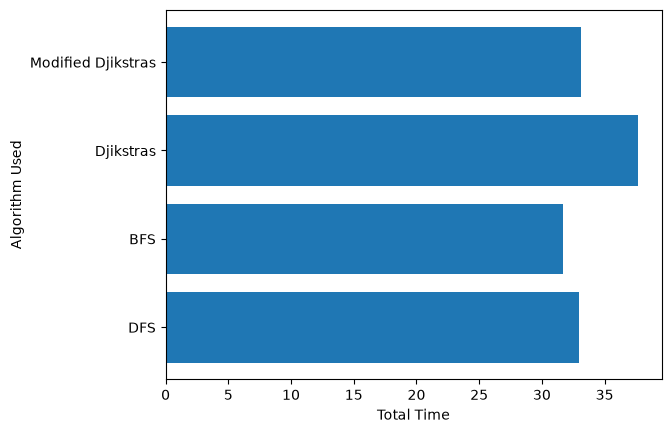

[32.978554248809814, 31.65529990196228, 37.66059231758118, 33.08423638343811]


In [27]:
timealgosumdf = pd.DataFrame({'Algorithms': algos, 'Times': timessum})

def addlabels(x,y):
    for i in range(len(x)):
        plt.text(i, y[i], y[i], ha = 'center')

fig, ax = plt.subplots()

ax.barh(timealgosumdf.Algorithms, timealgosumdf.Times)
ax.set_xlabel('Total Time')
ax.set_ylabel('Algorithm Used')

plt.show()
print(timessum)

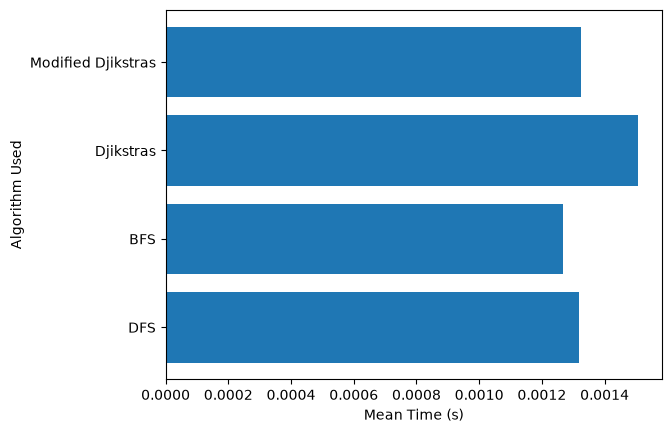

[0.0013191421699523926, 0.0012662119960784911, 0.001506423692703247, 0.0013233694553375244]


In [28]:
timealgomeandf = pd.DataFrame({'Algorithms': algos, 'Times': timesmean})

fig, ax = plt.subplots()

ax.barh(timealgomeandf.Algorithms, timealgomeandf.Times)
ax.set_xlabel('Mean Time (s)')
ax.set_ylabel('Algorithm Used')

plt.show()
print(timesmean)

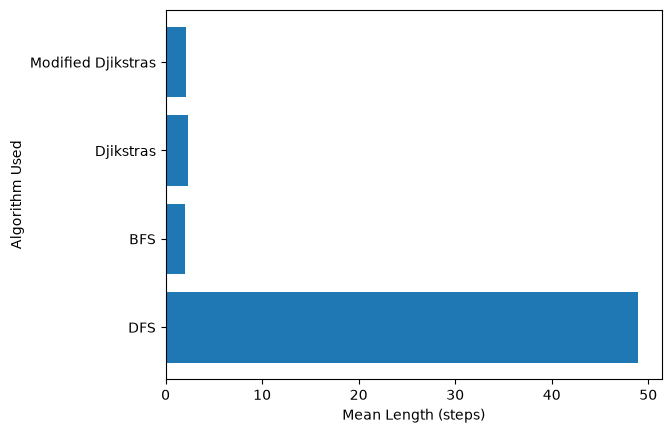

[48.93688, 2.05508, 2.34764, 2.12636]


In [29]:
answersmean = [[],[],[],[]]
answersmean[0] = mean(answers[0])
answersmean[1] = mean(answers[1])
answersmean[2] = mean(answers[2])
answersmean[3] = mean(answers[3])

anslen = pd.DataFrame({'Algorithms': algos, 'Lens': answersmean})

fig, ax = plt.subplots()

ax.barh(anslen.Algorithms, anslen.Lens)
ax.set_xlabel('Mean Length (steps)')
ax.set_ylabel('Algorithm Used')

plt.show()
print(answersmean)

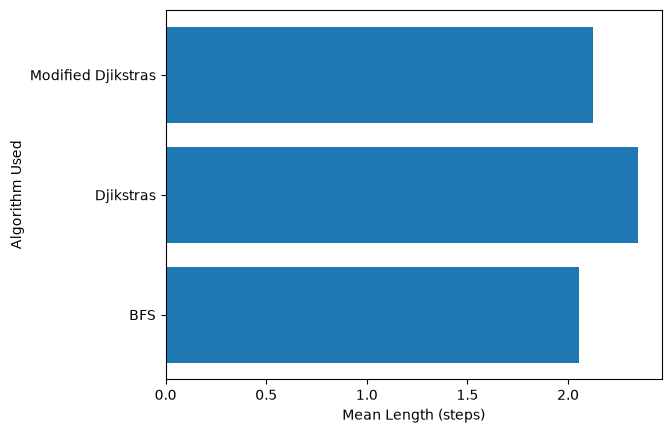

[2.05508, 2.34764, 2.12636]


In [30]:
answersmean = [[],[],[]]
answersmean[0] = mean(answers[1])
answersmean[1] = mean(answers[2])
answersmean[2] = mean(answers[3])

anslen = pd.DataFrame({'Algorithms': algos[1:4], 'Lens': answersmean})

fig, ax = plt.subplots()

ax.barh(anslen.Algorithms, anslen.Lens)
ax.set_xlabel('Mean Length (steps)')
ax.set_ylabel('Algorithm Used')

plt.show()
print(answersmean)

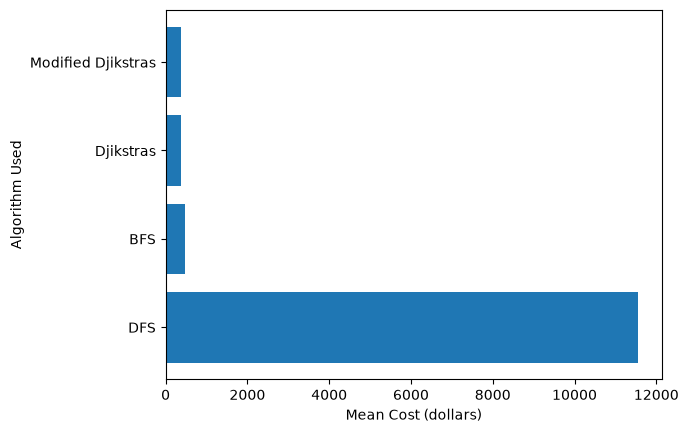

[11551.950248681285, 486.24110885870294, 373.68965930287726, 380.0688206782733]


In [31]:
costsmean = [[],[],[],[]]
costsmean[0] = mean(costs[0])
costsmean[1] = mean(costs[1])
costsmean[2] = mean(costs[2])
costsmean[3] = mean(costs[3])
costdf = pd.DataFrame({'Algorithms': algos, 'means': costsmean})

fig, ax = plt.subplots()

ax.barh(costdf.Algorithms, costdf.means)
ax.set_xlabel('Mean Cost (dollars)')
ax.set_ylabel('Algorithm Used')

plt.show()
print(costsmean)

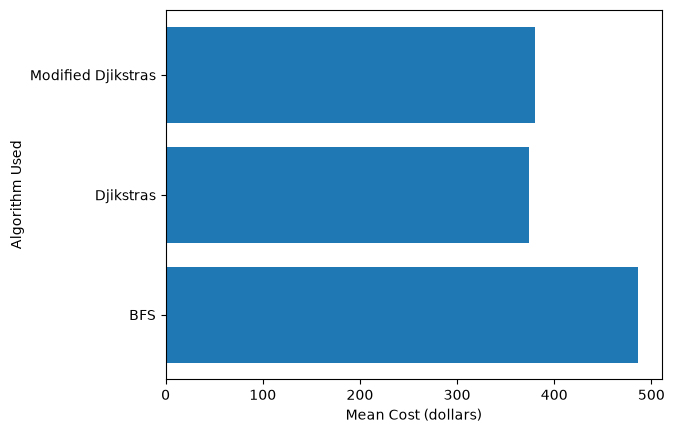

[486.24110885870294, 373.68965930287726, 380.0688206782733]


In [32]:
costsmean = [[],[],[]]
costsmean[0] = mean(costs[1])
costsmean[1] = mean(costs[2])
costsmean[2] = mean(costs[3])
costdf = pd.DataFrame({'Algorithms': algos[1:4], 'means': costsmean})

fig, ax = plt.subplots()

ax.barh(costdf.Algorithms, costdf.means)
ax.set_xlabel('Mean Cost (dollars)')
ax.set_ylabel('Algorithm Used')

plt.show()
print(costsmean)